# Tasks 2 and 4: Face Images, Image Features and the Facial Recognition Model

**Formative 2: Multimodal Data Preprocessing** · Image lead: Aime Igirimpuhwe ([@igaimerca](https://github.com/igaimerca))

This notebook walks through `scripts/image_pipeline.py` and `scripts/face_model.py` step by step:

1. Check that every member submitted 3 photos (neutral, smiling, surprised) with consistent names
2. Display every member's photos
3. Augment each photo 5 ways and save the copies
4. Extract face embeddings into `features/image_features.csv`
5. Train and evaluate the face model (accuracy, F1, log loss), holding out whole photos
6. Check that strangers are rejected as `unknown`, then save the model for the app

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import image_pipeline as ip
import face_model as fm

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
encoder = ip.FaceEncoder()

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

## 1. Collection check

Every file in `images/raw/` must be named `<member>_<expression>.jpg`, with all three expressions per member,
and must contain exactly one clearly detectable face. iPhone "High Efficiency" photos (`.heic`) are converted to `.jpg` first, upright,
and every photo's EXIF metadata is removed, because phones store the GPS location there and this repository is public. `unauthorized_face.jpg` is kept apart: it is only used to test that strangers are rejected.

In [2]:
converted = ip.convert_heic()
print("iPhone .heic photos converted to JPG:", converted or "none")
print("Location metadata removed from:", ip.remove_location_data() or "none")
report = ip.collection_report(encoder)
display(report)
print("Members:", sorted(report["member"].dropna().unique()))
print("Bad names:", list(report.loc[~report["valid_name"], "file"]) or "none")
print("Duplicates:", list(report.loc[report["duplicate"], "file"]) or "none")
print("Not exactly one face:", list(report.loc[report["faces"] != 1, "file"]) or "none")
print("Missing expressions:", ip.missing_expressions(report) or "none")

iPhone .heic photos converted to JPG: none
Location metadata removed from: none


,file,member,expression,valid_name,duplicate,faces,face_score,ok
0,aime_neutral.jpg,aime,neutral,True,False,1,0.857,True
1,aime_smiling.jpg,aime,smiling,True,False,1,0.852,True
2,aime_surprised.jpg,aime,surprised,True,False,1,0.882,True
3,sheja_neutral.jpg,sheja,neutral,True,False,1,0.920,True
4,sheja_smiling.jpg,sheja,smiling,True,False,1,0.923,True
5,sheja_surprised.jpg,sheja,surprised,True,False,1,0.916,True


Members: ['aime', 'sheja']
Bad names: none
Duplicates: none
Not exactly one face: none
Missing expressions: none


## 2. Every member's photos

Each photo is shown with the face box the YuNet detector found. That box is the only part of the image the model uses.

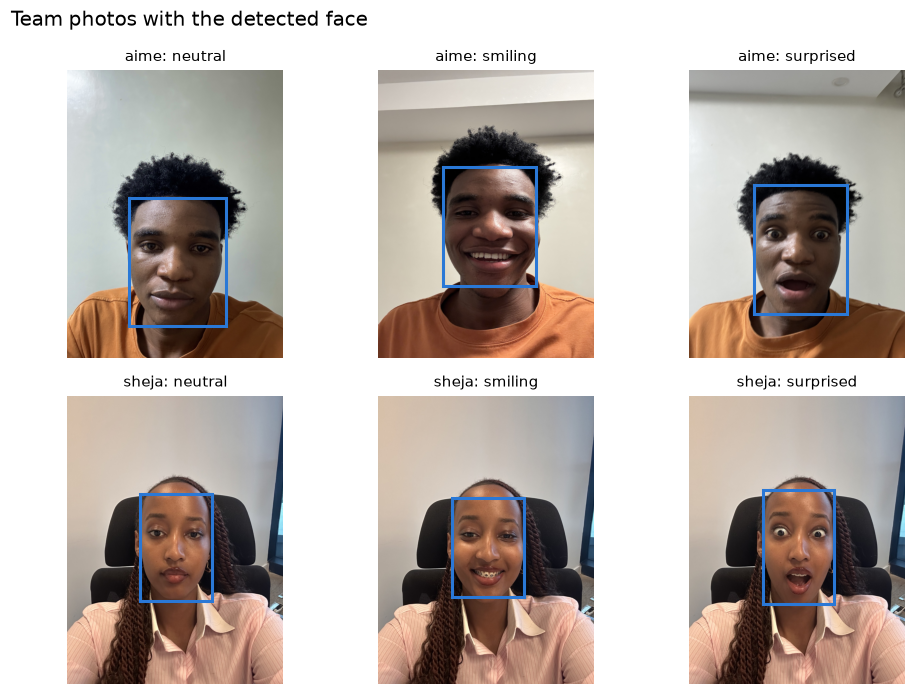

In [3]:
photos = ip.team_photos()
members = sorted({member for member, _ in photos})
fig, axes = plt.subplots(len(members), 3, figsize=(9, 3.2 * len(members)), squeeze=False)
for r, member in enumerate(members):
    for c, expression in enumerate(ip.EXPRESSIONS):
        ax = axes[r][c]
        ax.axis("off")
        path = photos.get((member, expression))
        if path is None:
            ax.set_title(f"{member}: {expression} missing", fontsize=9, color="#e34948")
            continue
        img = ip.read_image(path)
        face = encoder.detect(img)
        ax.imshow(rgb(img))
        if face is not None:
            x, y, w, h = face[:4]
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=COLORS[0], linewidth=2))
        ax.set_title(f"{member}: {expression}", fontsize=10)
fig.suptitle("Team photos with the detected face", fontsize=13, x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "image_01_member_photos.png", bbox_inches="tight")
plt.show()

## 3. Augmentations

Each photo gets 5 augmentations, each standing for a way a real login photo can differ from the enrolled one:

| Augmentation | What it simulates |
|---|---|
| `rotated` (15°) | a tilted head or phone |
| `flipped` (horizontal) | a mirrored front camera |
| `grayscale` | a poor or colourless camera |
| `brightened` (+50) | strong light or overexposure |
| `blurred` (Gaussian 9×9) | a shaky hand or out-of-focus shot |

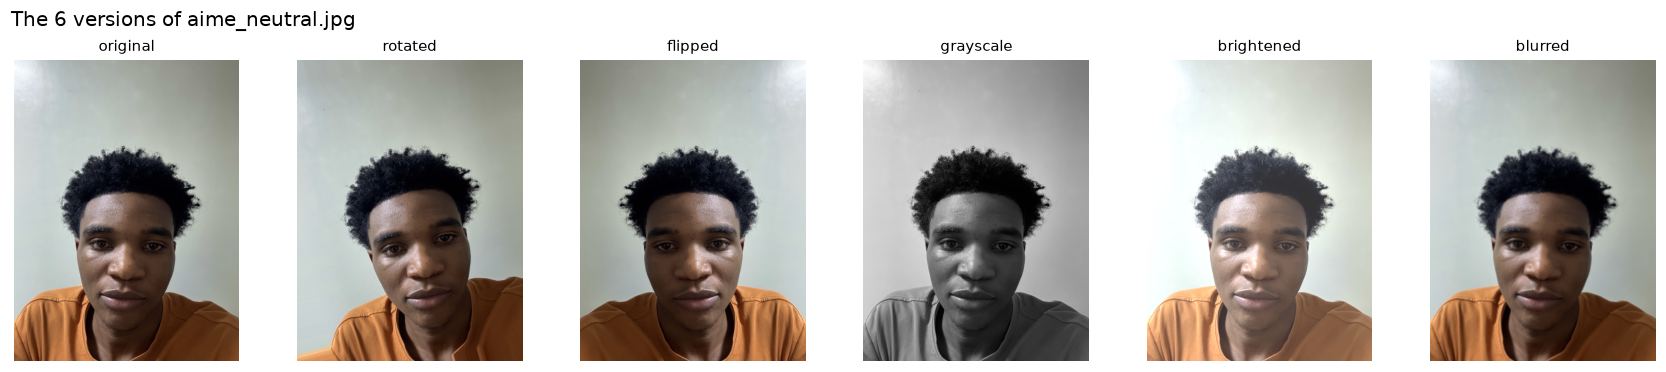

In [4]:
sample = next(iter(photos.values()))
versions = ip.augment(ip.read_image(sample))
fig, axes = plt.subplots(1, len(versions), figsize=(2.6 * len(versions), 3.4))
for ax, (name, img) in zip(axes, versions.items()):
    ax.imshow(rgb(img))
    ax.set_title(name, fontsize=10)
    ax.axis("off")
fig.suptitle(f"The 6 versions of {sample.name}", fontsize=13, x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "image_02_augmentations.png", bbox_inches="tight")
plt.show()

## 4. Feature extraction: face embeddings

For every version of every photo, YuNet finds the face and its 5 landmarks (eyes, nose, mouth corners).
An image is only used if it contains exactly one face. Then
SFace aligns and crops it to 112×112, and turns it into **128 numbers** (an embedding), scaled to length 1.
Photos of the same person give embeddings that point in nearly the same direction, so their cosine similarity is high.

`source_image` records which original photo each row came from, which section 5 uses to keep augmented copies out of the test set.

In [5]:
features, skipped = ip.build_features(encoder)
ip.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
features.to_csv(ip.FEATURES_FILE, index=False)
print(f"Saved {features.shape[0]} rows x {features.shape[1]} columns to features/image_features.csv")
print("Skipped images:", skipped or "none")
display(features.iloc[:6, :8])
display(pd.crosstab(features["member"], features["augmentation"]))

Saved 36 rows x 132 columns to features/image_features.csv
Skipped images: none


,member,expression,augmentation,source_image,emb_000,emb_001,emb_002,emb_003
0,aime,neutral,original,aime_neutral.jpg,-0.070996,-0.091259,-0.061165,0.062278
1,aime,neutral,rotated,aime_neutral.jpg,-0.066473,-0.095032,-0.054094,0.034281
2,aime,neutral,flipped,aime_neutral.jpg,-0.035115,-0.092158,-0.102005,0.058251
3,aime,neutral,grayscale,aime_neutral.jpg,-0.033974,-0.085142,-0.032607,0.029231
4,aime,neutral,brightened,aime_neutral.jpg,-0.065314,-0.115871,-0.022191,0.016416
5,aime,neutral,blurred,aime_neutral.jpg,-0.046872,-0.098298,-0.053360,0.003370


augmentation,blurred,brightened,flipped,grayscale,original,rotated
member,,,,,,
aime,3,3,3,3,3,3
sheja,3,3,3,3,3,3


### Do the embeddings separate the members?

Two views of the same question: a 2-D projection of all rows (PCA), and the cosine similarity between every pair of original photos.

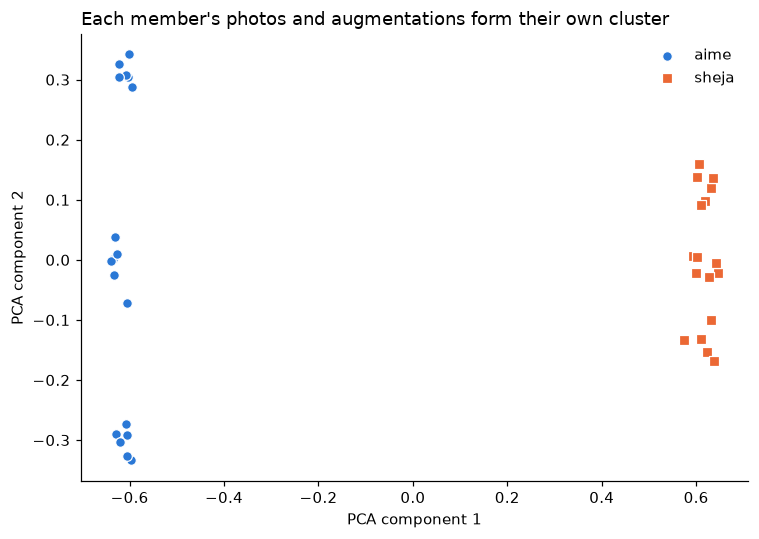

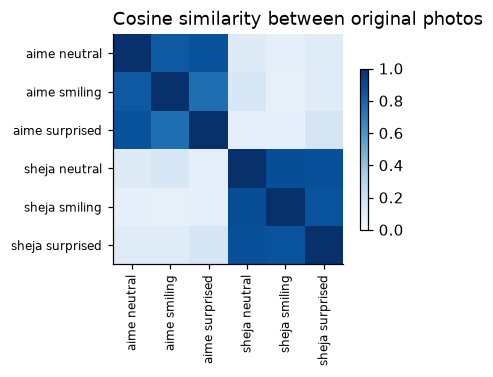

In [6]:
X = features[ip.EMBEDDING_COLUMNS].to_numpy()
points = PCA(n_components=2, random_state=0).fit_transform(X)
markers = ["o", "s", "^", "D", "v", "P"]
fig, ax = plt.subplots(figsize=(7, 5))
for i, member in enumerate(members):
    rows = features["member"].to_numpy() == member
    ax.scatter(points[rows, 0], points[rows, 1], s=40, color=COLORS[i % len(COLORS)], marker=markers[i % len(markers)],
               edgecolor="white", linewidth=0.8, label=member)
ax.set_title("Each member's photos and augmentations form their own cluster", loc="left", fontsize=12)
ax.set_xlabel("PCA component 1")
ax.set_ylabel("PCA component 2")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "image_03_embeddings_pca.png", bbox_inches="tight")
plt.show()

originals = features[features["augmentation"] == "original"].reset_index(drop=True)
E = originals[ip.EMBEDDING_COLUMNS].to_numpy()
labels = originals["member"] + " " + originals["expression"]
fig, ax = plt.subplots(figsize=(1 + 0.55 * len(labels), 0.5 + 0.5 * len(labels)))
im = ax.imshow(E @ E.T, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set_title("Cosine similarity between original photos", loc="left", fontsize=12)
fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(FIGURES / "image_04_similarity_matrix.png", bbox_inches="tight")
plt.show()

## 5. Facial recognition model

**Model:** Logistic Regression on the 128 embedding numbers. With few photos per person and well-separated embeddings,
a simple linear model is enough, and its probabilities give a meaningful log loss.

**Evaluation:** `StratifiedGroupKFold` grouped by `source_image`. In each fold, one original photo per member **and all 5 of its augmented copies**
are held out. Testing on a rotated copy of a training photo would overstate accuracy, because the model would have seen that exact face.

,held-out score
accuracy,1.000
f1_macro,1.000
log_loss,0.044
accepted_correctly,1.000
lowest_genuine_similarity,0.799


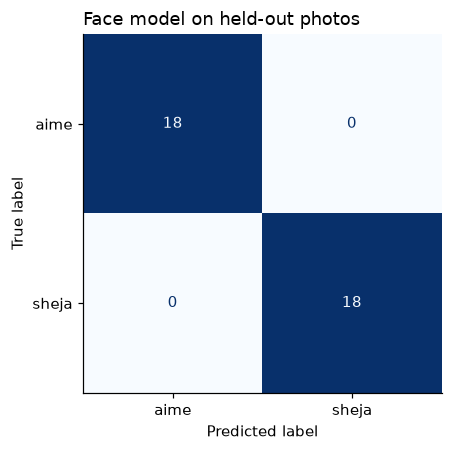

,accuracy
augmentation,
blurred,1.0
brightened,1.0
flipped,1.0
grayscale,1.0
original,1.0
rotated,1.0


In [7]:
held_out, probabilities, classes = fm.evaluate(features)
scores = fm.metrics(held_out, probabilities, classes)
display(pd.Series(scores, name="held-out score").round(3).to_frame())

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(held_out["member"], held_out["predicted"], labels=classes, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set_title("Face model on held-out photos", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "image_05_confusion_matrix.png", bbox_inches="tight")
plt.show()

correct = held_out.assign(accuracy=held_out["predicted"] == held_out["member"])
display(correct.groupby("augmentation")["accuracy"].mean().round(3).to_frame())

## 6. Rejecting strangers: the `unknown` decision

A classifier always names one of the members, even for a stranger. So `predict_face` only accepts a face when it is also
**close to that member's reference face** (the average embedding of their original photos): cosine similarity of at least **0.363**,
the threshold the SFace authors publish for "same person". Comparing against one reference per member, not against every augmented copy,
keeps that threshold as calibrated (one face against one face). An image with more than one face is rejected outright.

To check this on our own data, each member is removed from training in turn and treated as a stranger.
Their photos should all come back `unknown`, and their similarities should sit below the threshold, while genuine held-out photos sit above it.

,left_out,images,rejected,highest_similarity
0,aime,18,18,0.124
1,sheja,18,18,0.173


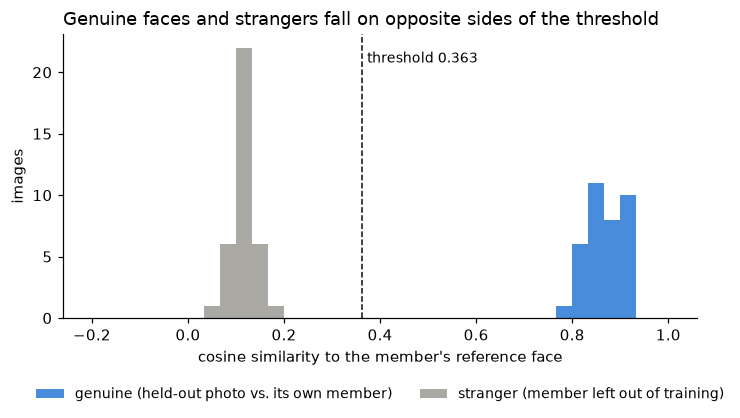

Lowest genuine similarity: 0.799 · highest stranger similarity: 0.173


In [8]:
impostors = fm.impostor_test(features)
display(impostors.drop(columns="similarities"))

genuine = held_out["genuine_similarity"].astype(float).to_numpy()
strangers = np.concatenate(impostors["similarities"].to_list()) if len(impostors) else np.array([])
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(-0.2, 1, 37)
ax.hist(genuine, bins=bins, color=COLORS[0], alpha=0.85, label="genuine (held-out photo vs. its own member)")
if len(strangers):
    ax.hist(strangers, bins=bins, color="#9b9a94", alpha=0.85, label="stranger (member left out of training)")
ax.axvline(fm.SIMILARITY_THRESHOLD, color="#0b0b0b", linestyle="--", linewidth=1)
ax.text(fm.SIMILARITY_THRESHOLD + 0.01, ax.get_ylim()[1] * 0.9, f"threshold {fm.SIMILARITY_THRESHOLD}", fontsize=9)
ax.set_xlabel("cosine similarity to the member's reference face")
ax.set_ylabel("images")
ax.set_title("Genuine faces and strangers fall on opposite sides of the threshold", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "image_06_threshold.png", bbox_inches="tight")
plt.show()
print(f"Lowest genuine similarity: {genuine.min():.3f}" + (f" · highest stranger similarity: {strangers.max():.3f}" if len(strangers) else ""))

## 7. Final model, unauthorized face and `predict_face`

The final model is trained on every row and saved to `models/face_model.joblib`. The app calls `predict_face(image_path)`,
which returns the member's name or `"unknown"`.

The unauthorized photo (`images/raw/unauthorized_face.jpg`, a public-domain NASA portrait from scikit-image, of someone outside the team)
is tested in all 6 versions.

In [9]:
model = fm.fit(features)
fm.MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
import joblib
joblib.dump(model, fm.MODEL_FILE)
fm._load.cache_clear()
print("Saved", fm.MODEL_FILE.relative_to(ROOT))

display(fm.unauthorized_test(model, encoder))

unauthorized = sorted(p for p in ip.RAW.glob("unauthorized*") if p.suffix.lower() in ip.IMAGE_SUFFIXES)
one_per_member = [next(p for (m, _), p in sorted(photos.items()) if m == member) for member in members]
for path in one_per_member + unauthorized:
    d = fm.face_details(path)
    print(f"predict_face({path.name!r:<26}) -> {d['member']:<10} (similarity {d['similarity']:.2f}, probability {d['probability']:.2f})")

Saved models/face_model.joblib


,image,augmentation,result,closest_member,similarity
0,unauthorized_face.jpg,original,unknown,aime,0.175
1,unauthorized_face.jpg,rotated,unknown,aime,0.109
2,unauthorized_face.jpg,flipped,unknown,aime,0.187
3,unauthorized_face.jpg,grayscale,unknown,aime,0.159
4,unauthorized_face.jpg,brightened,unknown,aime,0.147
5,unauthorized_face.jpg,blurred,unknown,aime,0.118


predict_face('aime_neutral.jpg'        ) -> aime       (similarity 0.96, probability 0.98)
predict_face('sheja_neutral.jpg'       ) -> sheja      (similarity 0.96, probability 0.97)
predict_face('unauthorized_face.jpg'   ) -> unknown    (similarity 0.18, probability 0.57)


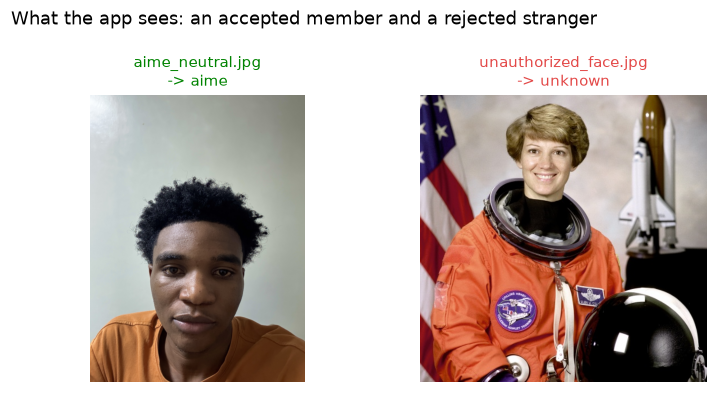

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, path in zip(axes, [one_per_member[0], *unauthorized[:1]]):
    result = fm.predict_face(path)
    ax.imshow(rgb(ip.read_image(path)))
    ax.set_title(f"{path.name}\n-> {result}", fontsize=10, color="#008300" if result != fm.UNKNOWN else "#e34948")
    ax.axis("off")
fig.suptitle("What the app sees: an accepted member and a rejected stranger", fontsize=12, x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "image_07_predict_face.png", bbox_inches="tight")
plt.show()